# Read in Clean Dataset

Import your packages

In [ ]:
using Base.Threads
println(nthreads())
#fm.fontManager.addfont("/Users/paola/Library/Fonts/lmroman10-regular.otf")


4


UndefVarError: UndefVarError: `fm` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [2]:
import Pkg
# This installs only the modern, compatible versions
Pkg.add(["DataFrames", "CSV", "InlineStrings", "Plots", "LaTeXStrings",
"Colors","StatsPlots", "Statistics", "XLSX", "Dates", "StatsBase", 
"CategoricalArrays", "Missings", "Chain", "FreqTables", "Glob", "MLJ",
"DecisionTree", "XGBoost", "LoggingExtras", "IJulia", "Parquet2", "OneHotArrays", "Distributions"])
using DataFrames, CSV, Statistics, Dates, Logging, Parquet2, Glob
using Plots, StatsPlots, DataFrames, StatsBase, Dates, Printf, Colors
using DecisionTree, LaTeXStrings
using Base.Threads, Distributions
using XGBoost
using OneHotArrays


    Updating registry at `~/.julia/registries/General.toml`
   Resolving package versions...
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`


In [3]:
Plots.reset_defaults()
gr()
default(
    fontfamily = "Computer Modern",
    titlefontsize = 16,
    guidefontsize = 14,
    tickfontsize = 12
)

Read in your file

In [4]:
filename = "05122026_df_final.parquet"
# Load the parquet file
ds = Parquet2.Dataset(filename)
# Convert it to a DataFrame
df_big = DataFrame(ds)
stats_df = describe(df_big, :eltype, :nmissing, :nunique, :min, :max, :median, :mean, :std)



Row,variable,eltype,nmissing,nunique,min,max,median,mean,std
,Symbol,DataType,Int64,Union…,Any,Any,Union…,Union…,Union…
1,award_type_code,String,0,4,A,D,,,
2,awarding_office_code_threeletter,String,0,10,FA0,FA9,,,
3,c8a_program_participant,Bool,0,,false,true,0.0,0.10085,0.301131
4,commercial_item_acquisition_procedures_code,String,0,3,A,Other,,,
5,construction_wage_rate_requirements_code,Bool,0,,false,true,0.0,0.0898637,0.285987
6,contracting_officers_determination_of_business_size_code,Bool,0,,false,true,1.0,0.613876,0.48686
7,corporate_entity_not_tax_exempt,Bool,0,,false,true,1.0,0.615983,0.486363
8,cost_or_pricing_data_code,Bool,0,,false,true,0.0,0.0677948,0.251394
9,dod_claimant_program_code,String,0,25,A1A,S1,,,


In [5]:
#vscodedisplay(stats_df)
#vscodedisplay(names(df))
shape = size(df_big)
println("The dataset has $(shape[1]) rows and $(shape[2]) columns.")

The dataset has 429517 rows and 46 columns.


In [6]:
# filter out micropurchase threhold
df = filter(row -> row.log_award_amount >= 4, df_big)
shape = size(df)
println("The dataset has $(shape[1]) rows and $(shape[2]) columns.")

The dataset has 352087 rows and 46 columns.


# PLOTS!

### Plot original distribution

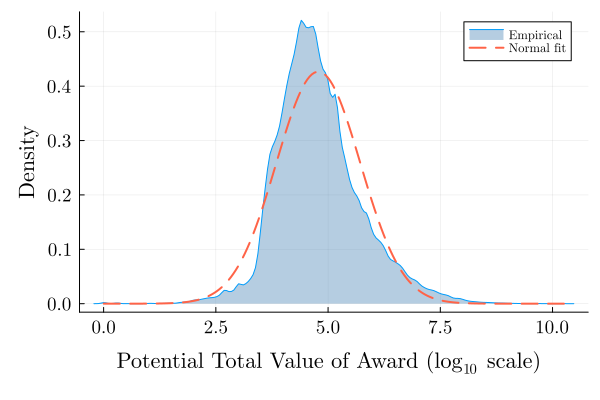

In [7]:
using Distributions
gr()

log_vals = df_big.log_award_amount

# fit a normal distribution to your data
fitted_normal = fit(Normal, log_vals)

# x range for the overlay
x_range = range(minimum(log_vals), maximum(log_vals), length=200)

# density plot
p = StatsPlots.density(log_vals,
    xlabel = "",
    ylabel = "Density",
    label = "Empirical",
    fill = (0, 0.4, :steelblue),
    left_margin = 5Plots.mm,
    bottom_margin = 15Plots.mm)

# overlay normal curve
plot!(p, x_range, pdf.(fitted_normal, x_range),
    label = "Normal fit",
    color = :tomato,
    linewidth = 2,
    linestyle = :dash)


# place label manually — tweak y value to move it up/down
annotate!(p, 5.0, -0.12, text(L"Potential Total Value of Award (log$_{10}$ scale)", font(14,"Computer Modern", ), :center))
#savefig(p, "figures/log_award_amount_density_plot.pdf")

### Plot MPT Distribution

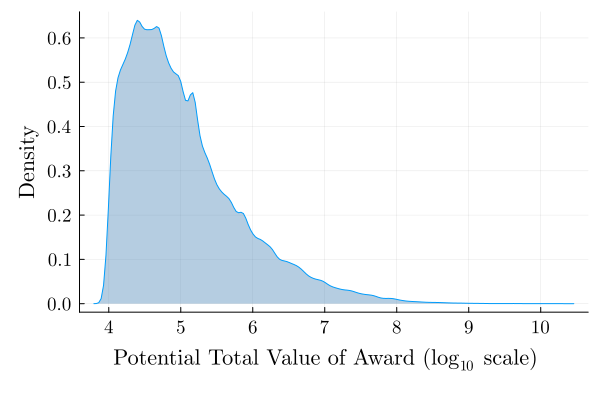

In [8]:


log_vals = df.log_award_amount

# fit a normal distribution to your data
fitted_normal = fit(Normal, log_vals)

# x range for the overlay
x_range = range(minimum(log_vals), maximum(log_vals), length=200)

p = StatsPlots.density(log_vals,
    xlabel = "",   # remove it
    ylabel = "Density",
    label = false,
    fill = (0, 0.4, :steelblue),
    left_margin = 5Plots.mm,
    bottom_margin = 15Plots.mm)

# place label manually — tweak y value to move it up/down
annotate!(p, 7.0, -0.14, text(L"Potential Total Value of Award (log$_{10}$ scale)", font(14,"Computer Modern", ), :center))
#savefig(p, "figures/log_award_amount_density_plot.pdf")

### Sort Columns

In [9]:
# 1. Identify all columns
all_cols = names(df)

# 2. Separate the "special" column from the rest
fixed_col = "log_award_amount"
other_cols = filter(c -> c != fixed_col, all_cols)

# 3. Sort the rest alphabetically
sort!(other_cols)

# 4. Combine them: fixed first, then the sorted remainder
new_order = vcat(fixed_col, other_cols)

# 5. Apply the new order to the DataFrame
select!(df, new_order)

stats_df = describe(df, :eltype, :nmissing, :nunique, :min, :max, :median, :mean, :std)
vscodedisplay(stats_df)


# MODEL TIME BB

Phase 1 — Baseline (no tuning)
  - Fit RF with default params, all features, evaluate with 5-fold CV
  - Fit XGB with default params, all features, evaluate with 5-fold CV
  - Record CV RMSE for both → this is your baseline

Phase 2 — Hyperparameter tuning
  - Grid search RF → best RF params → CV RMSE
  - Grid search XGB → best XGB params → CV RMSE
  - Compare tuned RF vs tuned XGB on CV RMSE

Phase 3 — Feature selection (on winning model or both)
  - Permutation importance → adaptive threshold → elbow curve
  - Refit with pruned features → CV RMSE
  - Compare pruned vs full feature model on CV RMSE

Phase 4 — Final evaluation
  - Take the single best model from Phase 3
  - Evaluate once on X_test
  - Report test RMSE, MAE, R²
  - Back-transform: predicted_dollars = 10 .^ predictions

## Phase 0 - Model Prep (splits, encoding, matrix conversion)

In [10]:
# ============================================================
# CONSISTENT RESULT TYPE
# ============================================================

struct ModelResult
    label::String
    rmse::Float64
    rmse_std::Float64
    mae::Float64
    mae_std::Float64
    r2::Float64
    r2_std::Float64
end

# ============================================================
# SCORING HELPER
# ============================================================

function score_predictions(y_true::Vector{Float64}, y_pred::AbstractVector)
    y_pred = Float64.(y_pred)  # convert Float32 to Float64 if needed
    residuals = y_true .- y_pred
    rmse      = sqrt(mean(residuals .^ 2))
    mae       = mean(abs.(residuals))
    ss_res    = sum(residuals .^ 2)
    ss_tot    = sum((y_true .- mean(y_true)) .^ 2)
    r2        = 1 - ss_res / ss_tot
    return rmse, mae, r2
end



score_predictions (generic function with 1 method)

### Split into testing/ training data

In [11]:
# identify categorical columns
categorical_cols = [col for col in names(df) if eltype(df[!, col]) <: Union{AbstractString, Symbol, Bool}]
#show(stdout, MIME"text/plain"(), categorical_cols)
# identify non-categorical columns
numerical_cols = setdiff(names(df), categorical_cols)
#make "solicitation_to_start_date_missing" a categorical colunn
if "solicitation_to_start_date_missing" in numerical_cols
    push!(categorical_cols, "solicitation_to_start_date_missing")
    numerical_cols = setdiff(numerical_cols, ["solicitation_to_start_date_missing"])
end


5-element Vector{String}:
 "log_award_amount"
 "number_of_offers_received"
 "performance_start_year"
 "potential_length_of_performance"
 "solicitation_to_start_date"

In [12]:
# combine(groupby(df, :performance_start_year), 
#     :log_award_amount => mean => :mean_log_award) |> 
#     x -> bar(x.performance_start_year, x.mean_log_award,
#         xlabel = "year",
#         ylabel = "mean log10 award amount",
#         title = "Mean Award Amount by Performance Start Year",
#         label = false,
#         color = :steelblue,
#         alpha = 0.7,
#         size = (800, 400),
#         titlefontweight = :bold,
#         guidefontweight = :bold)

In [13]:
using Random

function stratified_split(df::DataFrame, group_col::Symbol, train_ratio::Float64=0.8, seed::Int=42)
    Random.seed!(seed)
    
    train_idx = Int[]
    test_idx = Int[]
    
    for group in groupby(df, group_col)
        idx = collect(1:nrow(group))
        shuffle!(idx)
        n_train = round(Int, length(idx) * train_ratio)
        append!(train_idx, parentindices(group)[1][idx[1:n_train]])
        append!(test_idx, parentindices(group)[1][idx[n_train+1:end]])
    end
    
    return df[train_idx, :], df[test_idx, :]
end

df_train, df_test = stratified_split(df, :psc_group, 0.8)

println("Train size: $(nrow(df_train))")
println("Test size: $(nrow(df_test))")

# verify stratification held
train_dist = combine(groupby(df_train, :psc_group), nrow => :train_count)
test_dist = combine(groupby(df_test, :psc_group), nrow => :test_count)
println(leftjoin(train_dist, test_dist, on = :psc_group))

Train size: 281670
Test size: 70417
11×3 DataFrame
 Row │ psc_group  train_count  test_count 
     │ String     Int64        Int64?     
─────┼────────────────────────────────────
   1 │ G6               21358        5339
   2 │ G7               24559        6140
   3 │ G4               11294        2823
   4 │ G1               14840        3710
   5 │ G8               13250        3312
   6 │ G5               23842        5961
   7 │ G10              66574       16643
   8 │ Unknown          12295        3074
   9 │ G9               11839        2960
  10 │ G2               52627       13157
  11 │ G3               29192        7298


In [14]:
shape= size(df_train)

(281670, 46)

### ML Prep - target and categorical encoding

In [15]:
# get all categorical cols (you already have this)
cat_cols = [col for col in names(df_train) if 
    eltype(df_train[!, col]) <: Union{AbstractString, Symbol}]

# count unique values for each
cardinality = [(col, length(unique(skipmissing(df_train[!, col])))) 
    for col in cat_cols]
sort!(cardinality, by = x -> x[2])

ohe_cols = [col for (col, n) in cardinality if n <= 20]
target_encode_cols = [col for (col, n) in cardinality if n > 20]
binary_cols = [col for col in names(df_train) if 
    eltype(df_train[!, col]) <: Union{Bool}]
numerical_cols = setdiff(names(df_train), vcat(cat_cols, binary_cols, ohe_cols, target_encode_cols))
push!(binary_cols, "solicitation_to_start_date_missing")


# print them all so you can inspect
#foreach(x -> println(x[2], "\t", x[1]), cardinality)

20-element Vector{String}:
 "c8a_program_participant"
 "construction_wage_rate_requirements_code"
 "contracting_officers_determination_of_business_size_code"
 "corporate_entity_not_tax_exempt"
 "cost_or_pricing_data_code"
 "fed_biz_opps_code"
 "for_profit_organization"
 "historically_underutilized_business_zone_hubzone_firm"
 "labor_standards_code"
 "limited_liability_corporation"
 "manufacturer_of_goods"
 "minority_owned_business"
 "partnership_or_limited_liability_partnership"
 "performance_based_service_acquisition_code"
 "purchase_card_as_payment_method_code"
 "self_certified_small_disadvantaged_business"
 "subchapter_scorporation"
 "veteran_owned_business"
 "woman_owned_business"
 "solicitation_to_start_date_missing"

In [16]:
all_encoded = union(ohe_cols, target_encode_cols, binary_cols, numerical_cols)
all_cols = names(df_train)

println("OHE: ", length(ohe_cols))
println("Target encode: ", length(target_encode_cols))
println("Binary: ", length(binary_cols))
println("Total encoded: ", length(all_encoded))
println("Total df_train cols: ", length(all_cols))

missing_cols = setdiff(all_cols, string.(all_encoded))
extra_cols = setdiff(string.(all_encoded), all_cols)

println("\nColumns in df_train but not in any encoding list: ", missing_cols)
println("Columns in encoding lists but not in df_train: ", extra_cols)

OHE: 18
Target encode: 3
Binary: 20
Total encoded: 46
Total df_train cols: 46

Columns in df_train but not in any encoding list: String[]
Columns in encoding lists but not in df_train: String[]


In [17]:
using CategoricalArrays, Statistics

global_mean = mean(df_train.log_award_amount)

# ── 1. BINARY COLS → INT ──────────────────────────────────────────────────────
for col in binary_cols
    t = eltype(skipmissing(df_train[!, col]))
    if t <: Bool
        df_train[!, col] = Int.(df_train[!, col])
        df_test[!,  col] = Int.(df_test[!,  col])
    elseif t <: AbstractString
        df_train[!, col] = ifelse.(df_train[!, col] .== "Y", 1, 0)
        df_test[!,  col] = ifelse.(df_test[!,  col] .== "Y", 1, 0)
    end
    # already Int → do nothing
end

# ── 2. OHE COLS → SENTINEL + CATEGORICALARRAY ────────────────────────────────
sentinels = ["UNKNOWN", "MISSING_AGENCY_ID", "UNK", ""]
for col in ohe_cols
    levels_train = union(unique(skipmissing(df_train[!, col])), sentinels)
    df_train[!, col] = CategoricalArray(df_train[!, col], levels=levels_train)
    df_test[!,  col] = map(x -> coalesce(x, "UNKNOWN") in Set(levels_train) ? coalesce(x, "UNKNOWN") : "UNKNOWN", df_test[!, col])
    df_test[!,  col] = CategoricalArray(df_test[!, col], levels=levels_train)
end

# ── 3. TARGET ENCODE HIGH CARDINALITY COLS ───────────────────────────────────
for col in target_encode_cols
    col_sym = Symbol(col)
    enc_col = Symbol(string(col) * "_target_enc")
    col_means = combine(groupby(df_train, col_sym),
        :log_award_amount => mean => enc_col)
    leftjoin!(df_train, col_means, on=col_sym)
    leftjoin!(df_test,  col_means, on=col_sym)
    df_train[!, enc_col] = coalesce.(df_train[!, enc_col], global_mean)
    df_test[!,  enc_col] = coalesce.(df_test[!,  enc_col], global_mean)
    select!(df_train, Not(col_sym))
    select!(df_test,  Not(col_sym))
end

# ── 4. VERIFY ─────────────────────────────────────────────────────────────────
println("Train shape: ", size(df_train))
println("Test shape:  ", size(df_test))
println("Any missing in train: ", any(any(ismissing.(df_train[!, col])) for col in names(df_train)))

Train shape: (281670, 46)
Test shape:  (70417, 46)
Any missing in train: false


### Matrix conversion

In [18]:
using OneHotArrays

function to_matrix(df::DataFrame, target_col::Symbol, ohe_cols::Vector)
    exclude = Set([String(target_col)])
    feature_cols = [c for c in names(df) if !(c in exclude)]
    
    df_encoded = copy(df[!, feature_cols])
    
    for col in names(df_encoded)
        col_data = df_encoded[!, col]
        if nonmissingtype(eltype(col_data)) <: CategoricalArrays.CategoricalValue
            if col in string.(ohe_cols)
                # one hot encode
                lvls = levels(col_data)
                for lvl in lvls
                    df_encoded[!, Symbol(col * "_" * string(lvl))] = Int.(levelcode.(col_data) .== findfirst(==(lvl), lvls))
                end
                select!(df_encoded, Not(col))
            else
                df_encoded[!, col] = levelcode.(col_data)
            end
        end
    end
    
    X = Matrix{Float64}(df_encoded)
    y = Vector{Float64}(df[!, target_col])
    feature_cols_final = names(df_encoded)
    return X, y, feature_cols_final
end

X_train, y_train, feature_cols = to_matrix(df_train, :log_award_amount, ohe_cols)
X_test,  y_test,  _            = to_matrix(df_test,  :log_award_amount, ohe_cols)

println("Train: $(nrow(df_train)) rows | Test: $(nrow(df_test)) rows")
println("Features: $(length(feature_cols))")

Train: 281670 rows | Test: 70417 rows
Features: 215


## Phase 1 - Baseline

In [ ]:
function baseline_rf(X_train::Matrix{Float64}, y_train::Vector{Float64},
                     folds::Vector; seed::Int=42,
                     results_path::String="rf_baseline_results_100_0.7_10_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv")
    println("=== RF Baseline ===")
    n_subfeatures = round(Int, sqrt(size(X_train, 2)))
    rmse_scores, mae_scores, r2_scores = Float64[], Float64[], Float64[]

    for (i, fold) in enumerate(folds)
        model = build_forest(
            y_train[fold.train], X_train[fold.train, :],
            n_subfeatures, 100, 0.7, 10; rng=seed
        )
        rmse, mae, r2 = score_predictions(
            y_train[fold.val],
            apply_forest(model, X_train[fold.val, :])
        )
        push!(rmse_scores, rmse); push!(mae_scores, mae); push!(r2_scores, r2)
        @printf("  Fold %d — RMSE: %.4f | MAE: %.4f | R²: %.4f\n", i, rmse, mae, r2)
    end

    result = ModelResult("RF Baseline",
        mean(rmse_scores), std(rmse_scores),
        mean(mae_scores),  std(mae_scores),
        mean(r2_scores),   std(r2_scores))

    @printf("\n  CV RMSE: %.4f ± %.4f\n", result.rmse, result.rmse_std)
    @printf("  CV MAE:  %.4f ± %.4f\n",  result.mae,  result.mae_std)
    @printf("  CV R²:   %.4f ± %.4f\n",  result.r2,   result.r2_std)

    # save to csv
    df = DataFrame(
        label     = [result.label],
        fold_rmse = [join(round.(rmse_scores, digits=4), ", ")],
        fold_mae  = [join(round.(mae_scores,  digits=4), ", ")],
        fold_r2   = [join(round.(r2_scores,   digits=4), ", ")],
        rmse      = [result.rmse],
        rmse_std  = [result.rmse_std],
        mae       = [result.mae],
        mae_std   = [result.mae_std],
        r2        = [result.r2],
        r2_std    = [result.r2_std],
        timestamp = [string(now())],
        seed      = [seed],
    )
    CSV.write(results_path, df)
    println("  Results saved to $results_path")

    return result
end


function baseline_xgb(X_train::Matrix{Float64}, y_train::Vector{Float64},
                      folds::Vector; seed::Int=42,
                      results_path::String="xgb_baseline_results_100_10_0.1_0.8_0.8$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv")
    with_logger(NullLogger()) do
    println("\n=== XGBoost Baseline ===")
    rmse_scores, mae_scores, r2_scores = Float64[], Float64[], Float64[]

    for (i, fold) in enumerate(folds)
        dtrain = DMatrix(X_train[fold.train, :], label=y_train[fold.train])
        model  = xgboost(dtrain;
            num_round=100, max_depth=10, eta=0.1,
            subsample=0.8, colsample_bytree=0.8,
            objective="reg:squarederror", seed=seed)

        rmse, mae, r2 = score_predictions(
            y_train[fold.val],
            XGBoost.predict(model, DMatrix(X_train[fold.val, :]))
        )
        push!(rmse_scores, rmse); push!(mae_scores, mae); push!(r2_scores, r2)
        @printf("  Fold %d — RMSE: %.4f | MAE: %.4f | R²: %.4f\n", i, rmse, mae, r2)
    end

    result = ModelResult("XGB Baseline",
        mean(rmse_scores), std(rmse_scores),
        mean(mae_scores),  std(mae_scores),
        mean(r2_scores),   std(r2_scores))

    @printf("\n  CV RMSE: %.4f ± %.4f\n", result.rmse, result.rmse_std)
    @printf("  CV MAE:  %.4f ± %.4f\n",  result.mae,  result.mae_std)
    @printf("  CV R²:   %.4f ± %.4f\n",  result.r2,   result.r2_std)

    # save to csv
    df = DataFrame(
        label     = [result.label],
        fold_rmse = [join(round.(rmse_scores, digits=4), ", ")],
        fold_mae  = [join(round.(mae_scores,  digits=4), ", ")],
        fold_r2   = [join(round.(r2_scores,   digits=4), ", ")],
        rmse      = [result.rmse],
        rmse_std  = [result.rmse_std],
        mae       = [result.mae],
        mae_std   = [result.mae_std],
        r2        = [result.r2],
        r2_std    = [result.r2_std],
        timestamp = [string(now())],
        seed      = [seed],
    )
    CSV.write(results_path, df)
    println("  Results saved to $results_path")

    return result
    end
end

function make_folds(n::Int; k::Int=5, seed::Int=42)
    Random.seed!(seed)
    fold_idx  = shuffle(1:n)
    fold_size = div(n, k)
    folds = []
    for fold in 1:k
        val_start = (fold - 1) * fold_size + 1
        val_end   = fold == k ? n : fold * fold_size
        val_idx   = fold_idx[val_start:val_end]
        train_idx = setdiff(1:n, val_start:val_end)
        push!(folds, (train=train_idx, val=val_idx))
    end
    return folds
end

make_folds (generic function with 1 method)

### Fit RF and XGB with default params, all features, evaluate with 5-fold CV

In [ ]:
# shared folds — same for both models
folds = make_folds(size(X_train, 1); k=5, seed=42)

RUN_RF_BASELINE  = false
rf_input_file = "n=150/rf_baseline_results_100_0.7_10_2026-05-19_09-25-37.csv" # set to existing file if you want to skip RF baseline
RUN_XGB_BASELINE = false
xgb_input_file = "n=150/xgb_baseline_results_100_10_0.1_0.8_0.82026-05-19_09-28-54.csv" # set to existing file if you want to skip XGB baseline


if RUN_RF_BASELINE
    rf_baseline_result = baseline_rf(X_train, y_train, folds)
    # CSV.write(rf_output_file, DataFrame(
    # label=rf_baseline_result.label, rmse=rf_baseline_result.rmse, rmse_std=rf_baseline_result.rmse_std,
    # mae=rf_baseline_result.mae, mae_std=rf_baseline_result.mae_std,
    # r2=rf_baseline_result.r2, r2_std=rf_baseline_result.r2_std))
else
    df = CSV.read(rf_input_file, DataFrame)
    rf_baseline_result = ModelResult(df.label[1], df.rmse[1], df.rmse_std[1],
                                                  df.mae[1],  df.mae_std[1],
                                                  df.r2[1],   df.r2_std[1])
    println("=== RF Baseline (loaded from CSV) ===")
    @printf("  CV RMSE: %.4f ± %.4f\n", rf_baseline_result.rmse, rf_baseline_result.rmse_std)
    @printf("  CV MAE:  %.4f ± %.4f\n", rf_baseline_result.mae,  rf_baseline_result.mae_std)
    @printf("  CV R²:   %.4f ± %.4f\n", rf_baseline_result.r2,   rf_baseline_result.r2_std)
end



=== RF Baseline (loaded from CSV) ===
  CV RMSE: 0.5212 ± 0.0059
  CV MAE:  0.3978 ± 0.0040
  CV R²:   0.5722 ± 0.0085


In [21]:
if RUN_XGB_BASELINE
    xgb_baseline_result = baseline_xgb(X_train, y_train, folds)
    # CSV.write(xgb_output_file, DataFrame(
    #     label=xgb_baseline_result.label, rmse=xgb_baseline_result.rmse, rmse_std=xgb_baseline_result.rmse_std,
    #     mae=xgb_baseline_result.mae, mae_std=xgb_baseline_result.mae_std,
    #     r2=xgb_baseline_result.r2, r2_std=xgb_baseline_result.r2_std))
else
    df = CSV.read(xgb_input_file, DataFrame)
    xgb_baseline_result = ModelResult(df.label[1], df.rmse[1], df.rmse_std[1],
                                                   df.mae[1],  df.mae_std[1],
                                                   df.r2[1],   df.r2_std[1])
    println("\n=== XGBoost Baseline (loaded from CSV) ===")
    @printf("  CV RMSE: %.4f ± %.4f\n", xgb_baseline_result.rmse, xgb_baseline_result.rmse_std)
    @printf("  CV MAE:  %.4f ± %.4f\n", xgb_baseline_result.mae,  xgb_baseline_result.mae_std)
    @printf("  CV R²:   %.4f ± %.4f\n", xgb_baseline_result.r2,   xgb_baseline_result.r2_std)
end


=== XGBoost Baseline (loaded from CSV) ===
  CV RMSE: 0.4167 ± 0.0133
  CV MAE:  0.3109 ± 0.0092
  CV R²:   0.7265 ± 0.0163


## Phase 2 - Hyperparameter Tuning

### Grid search RF and XGB to find best model hyperparameters

In [26]:
function make_folds(n::Int; k::Int=5, seed::Int=42)
    Random.seed!(seed)
    fold_idx  = shuffle(1:n)
    fold_size = div(n, k)
    folds = []
    for fold in 1:k
        val_start = (fold - 1) * fold_size + 1
        val_end   = fold == k ? n : fold * fold_size
        val_idx   = fold_idx[val_start:val_end]
        train_idx = fold_idx[setdiff(1:n, val_start:val_end)]  # ✅ index into fold_idx first
        push!(folds, (train=train_idx, val=val_idx))
    end
    return folds
end

make_folds (generic function with 1 method)

In [ ]:
using CSV, DataFrames

function grid_search_rf(X_train::Matrix{Float64}, y_train::Vector{Float64},
                        folds::Vector; seed::Int=42,
                        results_path::String="rf_grid_search_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv")
    param_grid = [
        (n_trees=100, max_depth=15),
        (n_trees=100, max_depth=20),
        (n_trees=500, max_depth=10),
        (n_trees=500, max_depth=20)
    ]

    n_subfeatures = round(Int, sqrt(size(X_train, 2)))
    results       = Vector{ModelResult}(undef, length(param_grid))

    train_idxs = [fold.train for fold in folds]
    val_idxs   = [fold.val   for fold in folds]

    println("\n=== RF Grid Search ($(length(param_grid)) combos × $(length(folds)) folds) ===\n")

    _X           = X_train::Matrix{Float64}
    _y           = y_train::Vector{Float64}
    _train_idxs  = Vector{Vector{Int}}(train_idxs)
    _val_idxs    = Vector{Vector{Int}}(val_idxs)
    results_lock = ReentrantLock()

    @threads for i in 1:length(param_grid)
        params      = param_grid[i]
        rmse_scores = zeros(length(folds))
        mae_scores  = zeros(length(folds))
        r2_scores   = zeros(length(folds))

        for j in 1:length(folds)
            model = build_forest(
                _y[_train_idxs[j]], _X[_train_idxs[j], :],
                n_subfeatures, params.n_trees, 0.7, params.max_depth; rng=seed
            )
            rmse_scores[j], mae_scores[j], r2_scores[j] = score_predictions(
                _y[_val_idxs[j]],
                apply_forest(model, _X[_val_idxs[j], :])
            )
        end

        label = "RF t=$(params.n_trees)_d=$(params.max_depth)"
        result = ModelResult(label,
            mean(rmse_scores), std(rmse_scores),
            mean(mae_scores),  std(mae_scores),
            mean(r2_scores),   std(r2_scores))

        lock(results_lock) do
            results[i] = result
            @printf("  %s | RMSE: %.4f ± %.4f | R²: %.4f\n",
                result.label, result.rmse, result.rmse_std, result.r2)
        end
    end

    # save results to csv
    df = DataFrame(
        label    = [r.label    for r in results],
        rmse     = [r.rmse     for r in results],
        rmse_std = [r.rmse_std for r in results],
        mae      = [r.mae      for r in results],
        mae_std  = [r.mae_std  for r in results],
        r2       = [r.r2       for r in results],
        r2_std   = [r.r2_std   for r in results],
        timestamp = string(now()),
        seed      = seed,
    )
    CSV.write(results_path, df)
    println("\n  Results saved to $results_path")

    best_idx    = argmin(r.rmse for r in results)
    best_result = results[best_idx]
    best_params = param_grid[best_idx]

    println("\n  Best: $(best_result.label) | RMSE=$(round(best_result.rmse, digits=4))")
    #println("  Refitting on full training set with n_trees=500...")

    best_model = build_forest(
        y_train, X_train, n_subfeatures,
        500, 0.7, best_params.max_depth; rng=seed
    )

    return best_model, best_params, results,
           ModelResult("RF Tuned", best_result.rmse, best_result.rmse_std,
                                   best_result.mae,  best_result.mae_std,
                                   best_result.r2,   best_result.r2_std)
end


grid_search_rf (generic function with 1 method)

In [ ]:
# X_small    = X_train[1:500, :]
# y_small    = y_train[1:500]
# folds_small = make_folds(500; k=2, seed=42)

# v1_best_model, v1_best_params, v1_results, v1_summary = grid_search_rf(X_small, y_small, folds_small)
# rf_model_test, rf_params_test, rf_results_test, rf_tuned_test =
#     grid_search_rf(X_small, y_small, folds_small; seed=42)


=== RF Grid Search (3 combos × 2 folds) ===

  RF t=100_d=20 | RMSE: 0.7702 ± 0.0051 | R²: 0.3801
  RF t=100_d=15 | RMSE: 0.7702 ± 0.0051 | R²: 0.3801
  RF t=500_d=20 | RMSE: 0.7694 ± 0.0191 | R²: 0.3819

  Results saved to rf_grid_search_results_2026-05-19_11-13-19.csv

  Best: RF t=500_d=20 | RMSE=0.7694


(Ensemble of Decision Trees
Trees:      500
Avg Leaves: 55.364
Avg Depth:  11.904, (n_trees = 500, max_depth = 20), ModelResult[ModelResult("RF t=100_d=15", 0.7702202455589124, 0.005068931015910966, 0.6079418435023743, 0.016208756617679374, 0.3801013960234338, 0.03027968748986596), ModelResult("RF t=100_d=20", 0.7702202455589124, 0.005068931015910966, 0.6079418435023743, 0.016208756617679374, 0.3801013960234338, 0.03027968748986596), ModelResult("RF t=500_d=20", 0.7694020052175636, 0.019059775325457495, 0.6079052618095602, 0.007463998993566202, 0.3819391200013565, 0.007712310665673397)], ModelResult("RF Tuned", 0.7694020052175636, 0.019059775325457495, 0.6079052618095602, 0.007463998993566202, 0.3819391200013565, 0.007712310665673397))

In [ ]:
using Dates, Logging

xgb_grid_search_results = "n=150/allcol_xgb_grid_search_results_2026-05-12_18-10-59.csv"
rf_grid_search_results  = "n=150/rf_grid_search_results_2026-05-19_11-15-40.csv"

RUN_RF_GRID_SEARCH = false  # set to false after first run
RUN_XGB_GRID_SEARCH = false  # set to false after first run

if RUN_RF_GRID_SEARCH
    rf_model, rf_best_params, rf_cv_results, rf_tuned_result =
        grid_search_rf(X_train, y_train, folds)
else
    # load saved results
    println("\nLoading RF grid search results from CSV...")
    df = CSV.read(rf_grid_search_results, DataFrame)
    rf_cv_results = [ModelResult(row.label, row.rmse, row.rmse_std,
                                 row.mae,   row.mae_std,
                                 row.r2,    row.r2_std) for row in eachrow(df)]

    best_row    = df[argmin(df.rmse), :]
    best_depth  = parse(Int, match(r"\d+", best_row.label).match)
    rf_best_params = (n_trees=500, max_depth=best_depth)

    n_subfeatures = round(Int, sqrt(size(X_train, 2)))
    rf_model = build_forest(y_train, X_train, n_subfeatures,
                            500, 0.7, best_depth; rng=42);

    rf_tuned_result = ModelResult("RF Tuned", best_row.rmse, best_row.rmse_std,
                                              best_row.mae,  best_row.mae_std,
                                              best_row.r2,   best_row.r2_std)
end


false

In [31]:

function grid_search_xgb(X_train::Matrix{Float64}, y_train::Vector{Float64},
                         folds::Vector; seed::Int=42,
                         results_path::String="allcol_xgb_grid_search_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv")
    with_logger(NullLogger()) do
        
    param_grid = [
    (num_round=100, max_depth=30, eta=0.1, subsample=0.8),
    (num_round=600, max_depth=20, eta=0.01, subsample=0.8),
    (num_round=600, max_depth=30, eta=0.01, subsample=0.8),
    ]
    
    results = Vector{ModelResult}(undef, length(param_grid))

    println("\n=== XGBoost Grid Search ($(length(param_grid)) combos × $(length(folds)) folds) ===\n")

    for i in 1:length(param_grid)
        params      = param_grid[i]
        rmse_scores = zeros(length(folds))
        mae_scores  = zeros(length(folds))
        r2_scores   = zeros(length(folds))

        for (j, fold) in enumerate(folds)
            println("    combo $i/$(length(param_grid)) | fold $j/$(length(folds))...")
            dtrain = DMatrix(X_train[fold.train, :], label=y_train[fold.train])
            dval   = DMatrix(X_train[fold.val, :])
            model  = xgboost(dtrain;
                num_round=params.num_round, max_depth=params.max_depth,
                eta=params.eta, subsample=params.subsample,
                colsample_bytree=0.8, objective="reg:squarederror",
                nthread=Threads.nthreads(),
                seed=seed)

            rmse_scores[j], mae_scores[j], r2_scores[j] = score_predictions(
                y_train[fold.val],
                XGBoost.predict(model, dval)
            )
        end

        label     = "XGB d=$(params.max_depth) r=$(params.num_round)"
        results[i] = ModelResult(label,
            mean(rmse_scores), std(rmse_scores),
            mean(mae_scores),  std(mae_scores),
            mean(r2_scores),   std(r2_scores))

        @printf("  %s | RMSE: %.4f ± %.4f | R²: %.4f\n",
            results[i].label, results[i].rmse, results[i].rmse_std, results[i].r2)
    end

    # save results to csv
    df = DataFrame(
        label     = [r.label     for r in results],
        rmse      = [r.rmse      for r in results],
        rmse_std  = [r.rmse_std  for r in results],
        mae       = [r.mae       for r in results],
        mae_std   = [r.mae_std   for r in results],
        r2        = [r.r2        for r in results],
        r2_std    = [r.r2_std    for r in results],
        timestamp = [string(now()) for _ in results],
        seed      = [seed         for _ in results],
    )
    CSV.write(results_path, df)
    println("\n  Results saved to $results_path")

    best_idx    = argmin(r.rmse for r in results)
    best_result = results[best_idx]
    best_params = param_grid[best_idx]

    println("\n  Best: $(best_result.label) | RMSE=$(round(best_result.rmse, digits=4))")
    println("  Refitting on full training set...")

    dtrain_full = DMatrix(X_train, label=y_train)
    best_model  = xgboost(dtrain_full;
        num_round=best_params.num_round, max_depth=best_params.max_depth,
        eta=best_params.eta, subsample=best_params.subsample,
        colsample_bytree=0.8, objective="reg:squarederror",
        nthread=Threads.nthreads(),
        seed=seed)

    return best_model, best_params, results,
           ModelResult("XGB Tuned", best_result.rmse, best_result.rmse_std,
                                    best_result.mae,  best_result.mae_std,
                                    best_result.r2,   best_result.r2_std)
    end
end

grid_search_xgb (generic function with 1 method)

In [32]:

RUN_XGB_GRID_SEARCH = true  # set to false after first run

true

In [33]:

if RUN_XGB_GRID_SEARCH
    println("\nStarting XGBoost grid search...")
    xgb_model, xgb_best_params, xgb_cv_results, xgb_tuned_result =
        grid_search_xgb(X_train, y_train, folds)
else
    println("\nLoading XGBoost grid search results from CSV...")
    df = CSV.read(allcol_xgb_grid_search_results, DataFrame)
    xgb_cv_results = [ModelResult(row.label, row.rmse, row.rmse_std,
                                  row.mae,   row.mae_std,
                                  row.r2,    row.r2_std) for row in eachrow(df)]

    best_row       = df[argmin(df.rmse), :]
    depth_match    = match(r"d=(\d+)", best_row.label)
    round_match    = match(r"r=(\d+)", best_row.label)
    best_depth     = parse(Int, depth_match.match[3:end])
    best_numround  = parse(Int, round_match.match[3:end])
    xgb_best_params = (num_round=best_numround, max_depth=best_depth,
                       eta=0.01, subsample=0.9)

    dtrain_full = DMatrix(X_train, label=y_train)
    xgb_model   = xgboost(dtrain_full;
        num_round=xgb_best_params.num_round, max_depth=xgb_best_params.max_depth,
        eta=xgb_best_params.eta, subsample=xgb_best_params.subsample,
        colsample_bytree=0.8, objective="reg:squarederror", seed=42);

    xgb_tuned_result = ModelResult("XGB Tuned", best_row.rmse, best_row.rmse_std,
                                                best_row.mae,  best_row.mae_std,
                                                best_row.r2,   best_row.r2_std)
end


Starting XGBoost grid search...

=== XGBoost Grid Search (3 combos × 5 folds) ===

    combo 1/3 | fold 1/5...
    combo 1/3 | fold 2/5...
    combo 1/3 | fold 3/5...
    combo 1/3 | fold 4/5...
    combo 1/3 | fold 5/5...
  XGB d=30 r=100 | RMSE: 0.2353 ± 0.0377 | R²: 0.9111
    combo 2/3 | fold 1/5...
    combo 2/3 | fold 2/5...
    combo 2/3 | fold 3/5...
    combo 2/3 | fold 4/5...
    combo 2/3 | fold 5/5...
  XGB d=20 r=600 | RMSE: 0.2709 ± 0.0306 | R²: 0.8833
    combo 3/3 | fold 1/5...
    combo 3/3 | fold 2/5...
    combo 3/3 | fold 3/5...
    combo 3/3 | fold 4/5...
    combo 3/3 | fold 5/5...
  XGB d=30 r=600 | RMSE: 0.2328 ± 0.0356 | R²: 0.9131

  Results saved to allcol_xgb_grid_search_results_2026-05-19_11-47-18.csv

  Best: XGB d=30 r=600 | RMSE=0.2328
  Refitting on full training set...


(Booster(), (num_round = 600, max_depth = 30, eta = 0.01, subsample = 0.8), ModelResult[ModelResult("XGB d=30 r=100", 0.23532163193590955, 0.03774683966046942, 0.09696867383083357, 0.014048586924736, 0.9110984364579489, 0.02777424884928476), ModelResult("XGB d=20 r=600", 0.27091534200438694, 0.03056436269659779, 0.17209579192801633, 0.013473052527115332, 0.8833345221609925, 0.025794298824254637), ModelResult("XGB d=30 r=600", 0.23284703452002367, 0.0355727990056159, 0.10876853717212487, 0.013387247682465435, 0.9131147777741292, 0.02586923611302087)], ModelResult("XGB Tuned", 0.23284703452002367, 0.0355727990056159, 0.10876853717212487, 0.013387247682465435, 0.9131147777741292, 0.02586923611302087))

In [ ]:
# current best as of this run
# xgb_best_so_far = (num_round=600, max_depth=25, eta=0.03, subsample=0.9)
# RMSE: 0.6525 | R²: 0.5105

(num_round = 600, max_depth = 25, eta = 0.03, subsample = 0.9)

### Compare Tuned RF vs Tuned XGB on CV RMSE

In [34]:
# summary table
println("\n=== PHASE 1 vs PHASE 2 SUMMARY (CV RMSE) ===")
@printf("%-25s %-10s\n", "Model", "CV RMSE")
println("-"^35)
@printf("%-25s %.4f\n", "RF Baseline",    rf_baseline_result.rmse)
@printf("%-25s %.4f\n", "RF Tuned",       minimum(r.rmse for r in rf_cv_results))
@printf("%-25s %.4f\n", "XGBoost Baseline", xgb_baseline_result.rmse)
@printf("%-25s %.4f\n", "XGBoost Tuned",  minimum(r.rmse for r in xgb_cv_results))


=== PHASE 1 vs PHASE 2 SUMMARY (CV RMSE) ===
Model                     CV RMSE   
-----------------------------------
RF Baseline               0.5212
RF Tuned                  0.4319
XGBoost Baseline          0.4167
XGBoost Tuned             0.2328


In [116]:
default(
    fontfamily = "Computer Modern",
    titlefontsize = 16,
    guidefontsize = 22,
    tickfontsize = 14
)

In [230]:
using LaTeXStrings
function plot_model_comparison(results::Vector{ModelResult})
    labels    = [r.label for r in results]
    rmse_vals = [r.rmse  for r in results]
    rmse_stds = [r.rmse_std for r in results]
    mae_vals  = [r.mae   for r in results]
    r2_vals   = [r.r2    for r in results]
    mae_stds = [r.mae_std for r in results]
    r2_stds  = [r.r2_std  for r in results]

    # color by model family
    colors = [occursin("RF", r.label) ? :steelblue : :tomato for r in results]
    alphas = [occursin("Baseline", r.label) ? 0.5 : 1.0 for r in results]

    p1 = Plots.bar(labels, rmse_vals,
        yerror    = rmse_stds,
        xticks = false,
        #title     = "Cross-Validated RMSE",
        ylabel    = "RMSE",
        label     = false,
        color     = colors,
        alpha     = alphas,
        xrotation = 20,
        ylims     = (0, maximum(rmse_vals) * 1.2)
    )
    annotate!(p1, [(i-0.5, rmse_vals[i] + rmse_stds[i] + 0.03,
        text(string(round(rmse_vals[i], digits=3)), font(12, "Computer Modern"), :center)) for i in 1:length(results)])

    p2 = Plots.bar(labels, mae_vals,
        #title     = "CV MAE",
        xticks = false,
        yerror    = mae_stds,
        ylabel    = "MAE",
        label     = false,
        color     = colors,
        alpha     = alphas,
        xrotation = 20,
        ylims     = (0, maximum(mae_vals) * 1.2)
    )
    annotate!(p2, [(i-0.5, mae_vals[i] + mae_stds[i] + 0.02,
        text(string(round(mae_vals[i], digits=3)), font(12, "Computer Modern"), :center)) for i in 1:length(results)])

    p3 = Plots.bar(labels, r2_vals,
        #title     = L"CV $R^2$",
        xticks     = false,
        yerror    = r2_stds,
        ylabel    = L"$R^2$",
        label     = false,
        color     = colors,
        alpha     = alphas,
        xrotation = 20,
        ylims     = (0, 1.05)
    )
        annotate!(p3, [(i-0.5, r2_vals[i] + r2_stds[i] + 0.04,
        text(string(round(r2_vals[i], digits=3)), font(12, "Computer Modern"), :center)) for i in 1:length(results)])

p_legend = plot(
    zeros(1,4),
    label     = ["RF Baseline" "RF Tuned" "XGB Baseline" "XGB Tuned"],
    color     = [:steelblue :steelblue :tomato :tomato],
    alpha     = [0.5 1.0 0.5 1.0],
    t         = :bar,
    legend    = :inside,
    legendcolumns = 4,
    axis      = false,
    grid      = false,
    legendfontsize  = 16,
    ticks     = nothing,
    framestyle = :grid,
)

plot(p_legend, p1, p2, p3,
    layout = @layout([a{0.1h}; b c d]),
    size   = (1100, 480),
    left_margin   = 10Plots.mm,
    bottom_margin = 5Plots.mm,
    right_margin  = 5Plots.mm,
    top_margin    = 5Plots.mm,
    
)

# plot(p1, p2, p3, layout=(1, 3), size=(1100, 480),
#     left_margin=10Plots.mm, top_margin=15Plots.mm,
#     bottom_margin=5Plots.mm, right_margin=5Plots.mm,
#     legend=:outertop,        # moves legend above plot area
#     legendcolumns=4,         # all four entries in one row
# )
    # plot(p1, p2, p3, layout=(1, 3), size=(1100, 420), 
    #     left_margin=10Plots.mm, top_margin=20Plots.mm,
    #     bottom_margin=10Plots.mm, right_margin=5Plots.mm)

end
# plot baseline vs tuned for both models
#p = plot_model_comparison([rf_baseline_result, rf_tuned_result, xgb_baseline_result, xgb_tuned_result])

plot_model_comparison (generic function with 1 method)

In [ ]:
#savefig(p, "figures/CV_performance_rf_xgb_v2.pdf")

"/Users/paola/Docs/dev/phantom_project/project 1 - estimating potential total value/ALL-COL-FINAL/figures/CV_performance_rf_xgb_v2.pdf"

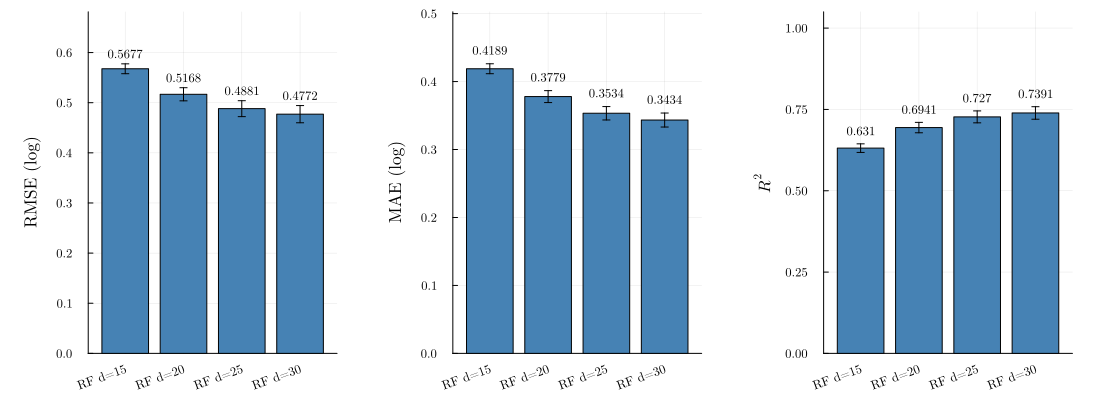

In [ ]:
#plot_model_comparison(rf_cv_results)

In [ ]:
plot_model_comparison(xgb_cv_results)

UndefVarError: UndefVarError: `text` not defined in `Main`
Hint: It looks like two or more modules export different bindings with this name, resulting in ambiguity. Try explicitly importing it from a particular module, or qualifying the name with the module it should come from.
Hint: a global variable of this name also exists in Plots.
    - Also exported by StatsPlots.
Hint: a global variable of this name also exists in GR.
Hint: a global variable of this name also exists in PyPlot.

## Phase 3 - Feature Selection on Winning Model

In [126]:
# determine winner from phase 2
winner_type   = rf_tuned_result.rmse <= xgb_tuned_result.rmse ? :rf : :xgb
winner_model  = winner_type == :rf ? rf_model : xgb_model
winner_tuned  = winner_type == :rf ? rf_tuned_result : xgb_tuned_result
winner_params_rf  = winner_type == :rf ? rf_best_params : nothing
winner_params_xgb = winner_type == :xgb ? xgb_best_params : nothing

println("Phase 2 winner: $(winner_tuned.label)")



Phase 2 winner: XGB Tuned


In [127]:
# validation slice from train for permutation importance
val_cut = round(Int, size(X_train, 1) * 0.8);
X_val   = X_train[val_cut+1:end, :];
y_val   = y_train[val_cut+1:end];

### Permutation importance, Adaptive Threshold, and Elbow Curve

In [ ]:
function permutation_importance(model, model_type::Symbol,
                                X::Matrix{Float64}, y::Vector{Float64},
                                feature_cols::Vector;
                                n_repeats::Int=5, seed::Int=42,
                                subsample::Int=50_000)
    Random.seed!(seed)

    # subsample for speed
    n   = length(y)
    idx = n <= subsample ? (1:n) : randperm(n)[1:subsample]
    X   = X[idx, :]
    y   = y[idx]

    # drop near-zero variance features
    active_mask = [std(X[:, j]) > 1e-6 for j in 1:size(X, 2)]
    active_idxs = findall(active_mask)
    println("  Active features: $(length(active_idxs)) / $(length(feature_cols)) (dropped $(sum(.!active_mask)) zero-variance)")

    # baseline
    if model_type == :rf
        baseline_preds = apply_forest(model, X)
    elseif model_type == :xgb
        baseline_preds = XGBoost.predict(model, DMatrix(X))
    end
    baseline_rmse = sqrt(mean((y .- baseline_preds) .^ 2))
    println("  Baseline RMSE: $(round(baseline_rmse, digits=4))")
    println("  Running $(length(active_idxs)) features × $n_repeats repeats on $(length(y)) rows...\n")

    importances = zeros(length(feature_cols))
    X_perm      = copy(X)  # one copy, reused across all features

    for j in active_idxs
        original_col = copy(X[:, j])
        fold_rmses   = zeros(n_repeats)

        for r in 1:n_repeats
            X_perm[:, j] = shuffle(original_col)
            if model_type == :rf
                fold_rmses[r] = sqrt(mean((y .- apply_forest(model, X_perm)) .^ 2))
            elseif model_type == :xgb
                fold_rmses[r] = sqrt(mean((y .- XGBoost.predict(model, DMatrix(X_perm))) .^ 2))
            end
        end

        X_perm[:, j]  = original_col
        importances[j] = mean(fold_rmses) - baseline_rmse
        println("  ✓ $(rpad(string(feature_cols[j]), 35)) importance: $(round(importances[j], digits=4))")
    end

    imp_df = DataFrame(
        feature                = string.(feature_cols),
        permutation_importance = importances
    )
    sort!(imp_df, :permutation_importance, rev=true)
    return imp_df
end
function adaptive_threshold(imp_df::DataFrame)
    vals      = imp_df.permutation_importance
    pos_vals  = vals[vals .> 0]
    μ         = mean(pos_vals)
    σ         = std(pos_vals)
    threshold = μ + σ

    total     = sum(pos_vals)
    imp_df[!, :cumulative_pct] = cumsum(max.(vals, 0) ./ total .* 100)

    println("\n=== Adaptive Threshold (μ + σ = $(round(threshold, digits=4))) ===")
    println(@sprintf("%-35s %-12s %-12s %s", "FEATURE", "IMPORTANCE", "CUMUL %", ""))
    println("-"^70)
    for row in eachrow(imp_df)
        marker = row.permutation_importance >= threshold ? " ◀ keep" : ""
        @printf("%-35s %-12.4f %-12.1f%%%s\n",
            row.feature, row.permutation_importance, row.cumulative_pct, marker)
    end

    kept = imp_df[imp_df.permutation_importance .>= threshold, :]
    @printf("\nFeatures kept: %d / %d\n", nrow(kept), nrow(imp_df))
    return kept, threshold
end
function _run_feature_sweep(ns::Vector{Int},
                             sorted_features::Vector,
                             feature_cols::Vector,
                             X_train::Matrix{Float64},
                             y_train::Vector{Float64},
                             folds::Vector;
                             model_type::Symbol,
                             seed::Int,
                             rf_params=nothing,
                             xgb_params=nothing,
                             xgb_round_cap::Int=100)

    results = DataFrame(n_features=Int[], rmse=Float64[], std=Float64[])

    for n in ns
        current_cols = [findfirst(==(f), string.(feature_cols)) for f in sorted_features[1:n]]
        filter!(!isnothing, current_cols)   # guard against unmatched names
        rmse_scores  = Float64[]

        for fold in folds
            X_tr = X_train[fold.train, current_cols]
            X_vl = X_train[fold.val,   current_cols]
            y_tr = y_train[fold.train]
            y_vl = y_train[fold.val]

            if model_type == :rf
                p     = rf_params
                model = build_forest(y_tr, X_tr,
                            round(Int, sqrt(n)),
                            500, 0.7, p.max_depth; rng=seed)
                preds = apply_forest(model, X_vl)

            elseif model_type == :xgb
                p            = xgb_params
                sweep_rounds = min(p.num_round, xgb_round_cap)
                model        = xgboost(DMatrix(X_tr, label=y_tr);
                                   num_round          = sweep_rounds,
                                   max_depth          = p.max_depth,
                                   eta                = p.eta,
                                   subsample          = p.subsample,
                                   colsample_bytree   = 0.8,
                                   objective          = "reg:squarederror",
                                   seed               = seed)
                preds = XGBoost.predict(model, DMatrix(X_vl))
            end

            push!(rmse_scores, sqrt(mean((y_vl .- preds) .^ 2)))
        end

        μ, σ = mean(rmse_scores), std(rmse_scores)
        push!(results, (n, μ, σ))
        @printf("  Top %3d features | RMSE: %.4f ± %.4f\n", n, μ, σ)
    end

    return results
end
function optimize_feature_count(X_train::Matrix{Float64},
                                 y_train::Vector{Float64},
                                 folds::Vector,
                                 imp_df::DataFrame,
                                 feature_cols::Vector,
                                 model_type::Symbol;
                                 seed::Int       = 42,
                                 coarse_step::Int = 10,
                                 xgb_round_cap::Int = 100,
                                 rf_params        = nothing,
                                 xgb_params       = nothing)

    with_logger(NullLogger()) do

    sorted_features = imp_df.feature
    max_n           = length(sorted_features)

    sweep_kwargs = (; model_type, seed, rf_params, xgb_params, xgb_round_cap)

    # ── Coarse pass ──────────────────────────────────────────────────────────
    coarse_ns = unique(vcat(1:2, coarse_step:coarse_step:max_n, max_n))
    println("\n=== Elbow Curve — Coarse Pass (step=$coarse_step, $(length(coarse_ns)) points) ===")

    results_log = _run_feature_sweep(coarse_ns, sorted_features, feature_cols,
                                      X_train, y_train, folds; sweep_kwargs...)

    coarse_best_n = results_log[argmin(results_log.rmse), :n_features]
    println("\n  Coarse best: n=$coarse_best_n | RMSE: $(round(minimum(results_log.rmse), digits=4))")

    # ── Fine pass: ±coarse_step window around coarse best ────────────────────
    fine_range = max(1, coarse_best_n - coarse_step + 1) : min(max_n, coarse_best_n + coarse_step - 1)
    fine_ns    = filter(n -> n ∉ results_log.n_features, collect(fine_range))

    if !isempty(fine_ns)
        println("\n=== Fine Pass (n=$(first(fine_range))–$(last(fine_range)), $(length(fine_ns)) new points) ===")
        fine_log = _run_feature_sweep(fine_ns, sorted_features, feature_cols,
                                       X_train, y_train, folds; sweep_kwargs...)
        append!(results_log, fine_log)
        sort!(results_log, :n_features)
    end

    # ── 1-SE Rule ────────────────────────────────────────────────────────────────
    best_idx    = argmin(results_log.rmse)
    best_rmse   = results_log.rmse[best_idx]
    best_std    = results_log.std[best_idx]
    se_band     = best_rmse + best_std

    one_se_row  = filter(row -> row.rmse <= se_band, results_log)
    sort!(one_se_row, :n_features)
    best_n      = one_se_row[1, :n_features]
    best_rmse   = one_se_row[1, :rmse]

    println("\n  ✓ 1-SE rule optimal feature count: $best_n | RMSE: $(round(best_rmse, digits=4)) (band ≤ $(round(se_band, digits=4)))")

    # ── Plot ─────────────────────────────────────────────────────────────────
    p = Plots.plot(results_log.n_features, results_log.rmse,
        ribbon    = results_log.std,
        fillalpha = 0.2,
        xlabel    = "Number of Features",
        ylabel    = "RMSE",
        label     = "CV RMSE",
        marker    = :circle,
        color     = :steelblue,
        linewidth = 2,
        size      = (700, 400))
    vline!(p, [best_n],
        label     = "optimal n=$best_n",
        color     = :tomato,
        linestyle = :dash,
        linewidth = 2)

    savefig(p, "figures/elbow_curve_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).pdf")
    display(p)

    return best_n, results_log
    end
end

optimize_feature_count (generic function with 1 method)

In [137]:
dtrain_full = DMatrix(X_train, label=y_train)
fast_winnner_model = xgboost(dtrain_full;
        num_round=100, max_depth=30,
        eta=xgb_best_params.eta, subsample=xgb_best_params.subsample,
        colsample_bytree=0.8, objective="reg:squarederror", seed=42);

┌ Info: XGBoost: starting training.
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:601
┌ Info: [1]	train-rmse:0.79068683759687441
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [2]	train-rmse:0.78489012520048174
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [3]	train-rmse:0.77884155156357282
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [4]	train-rmse:0.77338527867544693
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [5]	train-rmse:0.76736835424948380
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [6]	train-rmse:0.76141847427194032
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [7]	train-rmse:0.75557401577188676
└ @ XGBoost /Users/paola/.julia/packages/XGBoost/QaprL/src/booster.jl:451
┌ Info: [8]	train-rmse:0.75022482661670054
└ @ XGBoost /Users/paola/.ju

In [ ]:
RUN_PERMUTATION_IMPORTANCE = false
perm_imp_path = "n=150/permutation_importance_results_2026-05-22_16-11-11.csv"

RUN_ADAPTIVE_THRESHOLD     = false
adaptive_threshold_path = "n=150/adaptive_threshold_results_2026-05-22_16-48-46.csv"

RUN_ELBOW_CURVE            = false
elbow_curve_path = "n=150/elbow_curve_results_2026-05-22.csv"


false

In [143]:

if RUN_PERMUTATION_IMPORTANCE
    println("\nRunning permutation importance...")
    imp_df = permutation_importance(fast_winnner_model, winner_type, X_val, y_val, feature_cols)
    CSV.write("permutation_importance_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv", imp_df)
    # step 1 — permutation importance
else
    imp_df = CSV.read(perm_imp_path, DataFrame)
    println("Permutation importance loaded from CSV.")
end



Running permutation importance...
  Active features: 136 / 215 (dropped 79 zero-variance)
  Baseline RMSE: 0.3703
  Running 136 features × 5 repeats on 50000 rows...

  ✓ c8a_program_participant             importance: 0.0095
  ✓ construction_wage_rate_requirements_code importance: 0.013
  ✓ contracting_officers_determination_of_business_size_code importance: 0.0179
  ✓ corporate_entity_not_tax_exempt     importance: 0.0094
  ✓ cost_or_pricing_data_code           importance: 0.0067
  ✓ fed_biz_opps_code                   importance: 0.0198
  ✓ for_profit_organization             importance: 0.0031
  ✓ historically_underutilized_business_zone_hubzone_firm importance: 0.0053
  ✓ labor_standards_code                importance: 0.0046
  ✓ limited_liability_corporation       importance: 0.0093
  ✓ manufacturer_of_goods               importance: 0.0044
  ✓ minority_owned_business             importance: 0.0122
  ✓ number_of_offers_received           importance: 0.0436
  ✓ partnership_or_lim

"permutation_importance_results_2026-05-22_16-11-11.csv"

In [197]:

if RUN_ADAPTIVE_THRESHOLD
    println("\nRunning adaptive threshold...")
    kept_features, threshold = adaptive_threshold(imp_df)
    CSV.write("adaptive_threshold_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv", kept_features)
else
    kept_features = CSV.read(adaptive_threshold_path, DataFrame)
    threshold = mean(kept_features.permutation_importance) # or hardcode it
    println("Adaptive threshold loaded from CSV.")
end



Running adaptive threshold...

=== Adaptive Threshold (μ + σ = 0.0316) ===
FEATURE                             IMPORTANCE   CUMUL %      
----------------------------------------------------------------------
potential_length_of_performance     0.2101       17.2        % ◀ keep
solicitation_to_start_date_missing  0.1016       25.5        % ◀ keep
performance_start_year              0.0818       32.1        % ◀ keep
naics_code_sector_target_enc        0.0469       36.0        % ◀ keep
parent_award_type_code_B            0.0437       39.5        % ◀ keep
number_of_offers_received           0.0436       43.1        % ◀ keep
commercial_item_acquisition_procedures_code_D 0.0392       46.3        % ◀ keep
solicitation_to_start_date          0.0374       49.3        % ◀ keep
award_type_code_B                   0.0263       51.5        %
dod_claimant_program_code_target_enc 0.0239       53.4        %
purchase_card_as_payment_method_code 0.0205       55.1        %
fed_biz_opps_code            

"adaptive_threshold_results_2026-05-22_16-48-46.csv"

In [ ]:
# fm = pyimport("matplotlib.font_manager")
# fm.fontManager.addfont("/Users/paola/Library/Fonts/lmroman10-regular.otf")

# fonts = [f.name for f in fm.fontManager.ttflist]
# filter(f -> occursin("LM", f) || occursin("Latin", f) || occursin("Roman", f), fonts)

5-element Vector{String}:
 "Times New Roman"
 "Times New Roman"
 "Times New Roman"
 "Times New Roman"
 "Latin Modern Roman"

In [177]:
mpl = pyimport("matplotlib")
println(mpl.get_cachedir())

/Users/paola/.matplotlib


In [ ]:
# optimal_n = 12
# threshold = 0.0316
# top10     = first(imp_df, 10)
# matplotlib.rcParams["font.family"] = "Latin Modern Roman"
# matplotlib.ticker = pyimport("matplotlib.ticker")
# matplotlib.rcParams["mathtext.fontset"] = "Latin Modern Roman"


# features    = reverse(top10.feature)
# importances = reverse(top10.permutation_importance)

# fig, ax = subplots(figsize=(9, 7))
# #grid on
# ax.barh(1:10, importances, color="#4682B4", height=0.6, edgecolor="black", linewidth=0.8)
# ax.set_yticks(1:10)
# # title case + replace underscores with spaces
# features_clean = reverse([join(titlecase.(split(f, "_")), " ") for f in top10.feature])

# # then replace the yticklabels line with:
# ax.set_yticklabels(features_clean, fontsize=16, fontfamily="Latin Modern Roman")


# cutoff_x = threshold
# ax.axvline(cutoff_x, linestyle="--", color="tomato", linewidth=1.5)
# #ax.text(cutoff_x + 0.002, 15.5, "Threshold (\mu+ \sigma = $(round(threshold, digits=4)))", color="tomato", fontsize=12, fontfamily="Latin Modern Roman") #Times New Roman")
# ax.text(cutoff_x + 0.002, 10.5, "Threshold (\$\\mu + \\sigma\$ = $(round(threshold, digits=4)))",
#         color="tomato", fontsize=16, fontfamily="Latin Modern Roman")


#         # grid on (x axis only makes sense for a bar chart)
# ax.xaxis.grid(true, linestyle="-", linewidth=0.5, alpha=0.4, color="gray")
# ax.set_axisbelow(true)  # grid behind bars

# # cutoff_y = 15 - optimal_n + 0.5
# # ax.axhline(cutoff_y, linestyle="--", color="tomato", linewidth=1.5)
# # ax.text(maximum(importances) * 0.5, cutoff_y + 0.2,
# #         "n = $optimal_n cutoff", color="tomato", fontsize=9, fontfamily="Latin Modern Roman") #Times New Roman")

# ax.set_xlabel("Permutation Importance", fontfamily="Latin Modern Roman", fontsize=22, fontweight="bold")
# ax.set_ylabel("Top 10 Features", fontfamily="Latin Modern Roman", fontsize=22, fontweight="bold")
# #ax.set_title("Top 20 features — permutation importance", fontfamily="Latin Modern Roman")
# ax.spines["top"].set_visible(false)
# ax.spines["right"].set_visible(false)

# ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.2f"))
# for label in ax.get_xticklabels()
#     label.set_fontfamily("Latin Modern Roman")
#     label.set_fontsize(14)
#     #label.round = 3
# end
# #text(string(round(rmse_vals[i], digits=3)), font(12, "Computer Modern"), :center)

# tight_layout()
# gcf()
# #savefig("permutation_importance_top20.pdf", bbox_inches="tight")
# #PyPlot.savefig("figures/permutation_importance_top10.pdf", bbox_inches="tight", dpi=300)

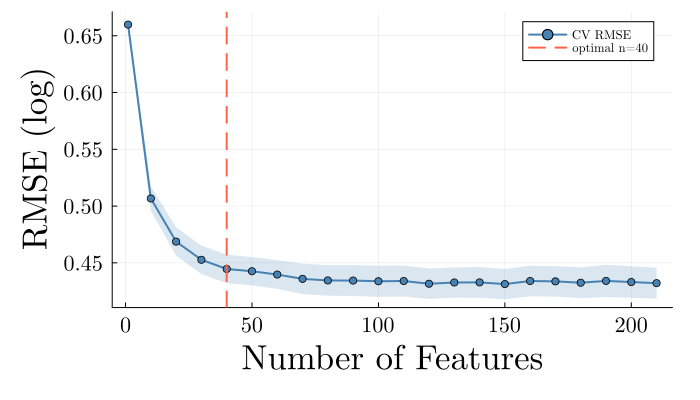

Elbow curve loaded from CSV. Best n=150


In [ ]:
elbow_curve_path= "elbow_curve_results_2026-05-22.csv"

if RUN_ELBOW_CURVE
    println("\nRunning elbow curve...")
    best_n, elbow_results = optimize_feature_count(
    X_train, y_train,
    folds,
    imp_df,              # output from adaptive_threshold — the kept features df
    feature_cols,        # your full feature column vector
    :xgb;               # or :rf
    seed        = 42,
    coarse_step = 10,
    xgb_round_cap = 100,
    xgb_params  = xgb_best_params)  # your named tuple from grid search)
    CSV.write("elbow_curve_results_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv", elbow_results)
    #savefig("elbow_curve_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).png")
else
    elbow_results = CSV.read(elbow_curve_path, DataFrame)
    best_n        = elbow_results[argmin(elbow_results.rmse), :n_features]
    println("Elbow curve loaded from CSV. Best n=$best_n")
    default(
    fontfamily = "Computer Modern",
    titlefontsize = 16,
    guidefontsize = 16,
    tickfontsize = 14)
    # rebuild plot from saved results
    plt = Plots.plot(elbow_results.n_features, elbow_results.rmse,
        ribbon    = elbow_results.std,
        fillalpha = 0.2,
        xlabel    = "Number of Features",
        ylabel    = "RMSE (log)",
        #title     = "Feature Count vs RMSE",
        label     = "CV RMSE",
        marker    = :circle,
        color     = :steelblue,
        linewidth = 2,
        size      = (700, 400),
        left_margin=8Plots.mm, top_margin=1Plots.mm,
        bottom_margin=10Plots.mm, right_margin=5Plots.mm)
    
    vline!(plt, [40],
        label     = "1-SE Criterion=40",
        color     = :tomato,
        linestyle = :dash,
        linewidth = 2)
        

    display(plt)



end

 

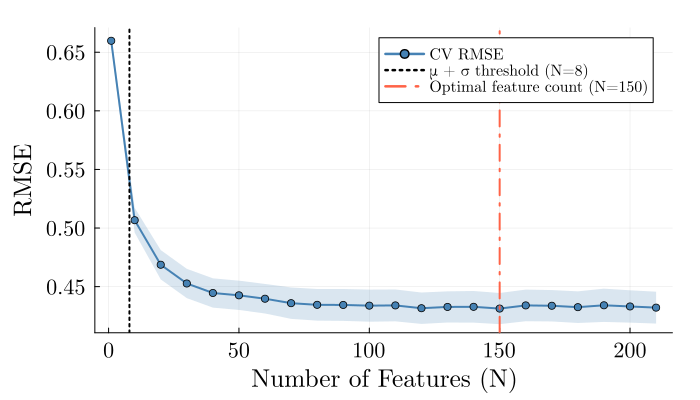

In [ ]:
default(
    fontfamily = "Computer Modern",
    guidefontsize = 16,
    tickfontsize = 14)

    # rebuild plot from saved results
    plt = Plots.plot(elbow_results.n_features, elbow_results.rmse,
        ribbon    = elbow_results.std,
        fillalpha = 0.2,
        xlabel    = "Number of Features (N)",
        ylabel    = "RMSE",
        #title     = "Feature Count vs RMSE",
        label     = "CV RMSE",
        marker    = :circle,
        color     = :steelblue,
        linewidth = 2,
        size      = (700, 400),
        left_margin=5Plots.mm, top_margin=5Plots.mm,
        bottom_margin=5Plots.mm, right_margin=5Plots.mm)
    
    vline!(plt, [8],
    label = "μ + σ threshold (N=8)",
    color     = :black,
    linestyle = :dot,
    linewidth = 2)

    vline!(plt, [150],
        label     = "Optimal feature count (N=150)",
        color     = :tomato,
        linestyle = :dashdot,
        linewidth = 2)

    plot!(plt, legendfontsize=10)
    #   vline!(plt, [50],
    #     label     = "Elbow Point: N=50",
    #     color     = :black,
    #     linestyle = :dashdot,
    #     linewidth = 2)

    display(plt)



In [ ]:
#Plots.savefig(plt, "figures/elbow_curve_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).pdf")

"/Users/paola/Docs/dev/phantom_project/project 1 - estimating potential total value/ALL-COL-FINAL/figures/elbow_curve_2026-05-23_14-06-29.pdf"

In [ ]:
#best_n = 40;
#best_n = 150;
#best_n=69;


In [385]:
top_features  = imp_df.feature[1:best_n]
top_col_idxs  = [findfirst(==(f), string.(feature_cols)) for f in top_features]
X_train_final = X_train[:, top_col_idxs]
X_test_final  = X_test[:,  top_col_idxs]

70417×69 Matrix{Float64}:
   46.0  0.0  2024.0  5.12826  0.0   1.0  …  0.0  0.0  5.07151  0.0  1.0  0.0
  364.0  0.0  2025.0  5.48628  1.0   0.0     0.0  0.0  5.07151  0.0  0.0  0.0
 1216.0  0.0  2024.0  4.87554  0.0   1.0     0.0  0.0  5.07151  1.0  0.0  0.0
    2.0  1.0  2019.0  4.94802  0.0   1.0     0.0  1.0  5.07151  1.0  0.0  0.0
  367.0  1.0  2011.0  5.20832  1.0  30.0     0.0  0.0  5.07151  0.0  1.0  0.0
  730.0  0.0  2023.0  5.48628  0.0   1.0  …  0.0  0.0  5.07151  0.0  0.0  0.0
 1825.0  1.0  2017.0  4.86189  0.0   1.0     0.0  0.0  5.07151  0.0  0.0  0.0
 1338.0  1.0  2015.0  5.48628  1.0   4.0     0.0  0.0  5.07151  0.0  1.0  0.0
  364.0  1.0  2016.0  5.48628  1.0   2.0     1.0  0.0  5.07151  0.0  0.0  0.0
 1764.0  0.0  2019.0  5.48628  1.0   2.0     0.0  0.0  5.07151  0.0  1.0  0.0
    ⋮                                ⋮    ⋱            ⋮                  
   44.0  1.0  2014.0  5.18426  1.0   1.0     0.0  0.0  5.07151  0.0  1.0  0.0
  364.0  0.0  2020.0  5.48628  1.0  19.0 

### Refit winning model with pruned features

In [386]:
# ============================================================
# PHASE 3 — FEATURE SELECTION + FINAL MODEL
# ============================================================

# --- Step 1: CV score the pruned model ---
function cv_score_pruned(X_train, y_train, folds, imp_df, best_n,
                         feature_cols, model_type;
                         rf_params=nothing, xgb_params=nothing, seed=42)
    with_logger(NullLogger()) do
        top_features = imp_df.feature[1:best_n]
        col_idx      = [findfirst(==(f), string.(feature_cols)) for f in top_features]
        X_pruned     = X_train[:, col_idx]

        rmse_scores, mae_scores, r2_scores = Float64[], Float64[], Float64[]

        for fold in folds
            X_tr = X_pruned[fold.train, :]
            X_vl = X_pruned[fold.val,   :]
            y_tr = y_train[fold.train]
            y_vl = y_train[fold.val]

            if model_type == :rf
                model = build_forest(y_tr, X_tr,
                    round(Int, sqrt(best_n)),
                    500, 0.7, rf_params.max_depth; rng=seed)
                preds = apply_forest(model, X_vl)
            elseif model_type == :xgb
                model = xgboost(DMatrix(X_tr, label=y_tr);
                    num_round=xgb_params.num_round, max_depth=xgb_params.max_depth,
                    eta=xgb_params.eta, subsample=xgb_params.subsample,
                    colsample_bytree=0.8, objective="reg:squarederror", seed=seed)
                preds = XGBoost.predict(model, DMatrix(X_vl))
            end

            rmse, mae, r2 = score_predictions(y_vl, preds)
            push!(rmse_scores, rmse)
            push!(mae_scores,  mae)
            push!(r2_scores,   r2)
        end

        prefix = model_type == :rf ? "RF" : "XGB"
        pruned_result = ModelResult("$(prefix) Pruned (top $(best_n))",
            mean(rmse_scores), std(rmse_scores),
            mean(mae_scores),  std(mae_scores),
            mean(r2_scores),   std(r2_scores))

        return pruned_result, col_idx
    end
end


# --- Step 2: refit winner on full training data ---
function refit_final(X_train, y_train, col_idx, model_type;
                     rf_params=nothing, xgb_params=nothing, seed=42)
    with_logger(NullLogger()) do
        X_sub = X_train[:, col_idx]
        n     = length(col_idx)

        if model_type == :rf
            return build_forest(y_train, X_sub,
                round(Int, sqrt(n)), 500, 0.7, rf_params.max_depth; rng=seed)
        elseif model_type == :xgb
            return xgboost(DMatrix(X_sub, label=y_train);
                num_round=xgb_params.num_round, max_depth=xgb_params.max_depth,
                eta=xgb_params.eta, subsample=xgb_params.subsample,
                colsample_bytree=0.8, objective="reg:squarederror",
                seed=seed, verbosity=0)
        end
    end
end


# --- Step 3: compare and pick winner ---
function select_final_model(winner_model, winner_tuned, pruned_model, pruned_result,
                            full_col_idx, pruned_col_idx;
                            r2_threshold::Float64=0.70,
                            r2_pct_diff::Float64=0.05,
                            save_path::String="results/model_comparison_n=69.csv")

    @printf("\n=== Final Model Selection ===\n")
    @printf("  %-35s RMSE: %.4f ± %.4f | R²: %.4f\n",
        winner_tuned.label, winner_tuned.rmse, winner_tuned.rmse_std, winner_tuned.r2)
    @printf("  %-35s RMSE: %.4f ± %.4f | R²: %.4f\n",
        pruned_result.label, pruned_result.rmse, pruned_result.rmse_std, pruned_result.r2)

    pct_diff = abs(pruned_result.r2 - winner_tuned.r2) / abs(winner_tuned.r2)
    @printf("\n  R² percent difference (full vs pruned): %.2f%%\n", pct_diff * 100)

    # ── save results to CSV ───────────────────────────────────────────────────
    comparison_df = DataFrame(
        label    = [winner_tuned.label,    pruned_result.label],
        rmse     = [winner_tuned.rmse,     pruned_result.rmse],
        rmse_std = [winner_tuned.rmse_std, pruned_result.rmse_std],
        mae      = [winner_tuned.mae,      pruned_result.mae],
        mae_std  = [winner_tuned.mae_std,  pruned_result.mae_std],
        r2       = [winner_tuned.r2,       pruned_result.r2],
        r2_std   = [winner_tuned.r2_std,   pruned_result.r2_std],
    )
    mkpath(dirname(save_path))
    CSV.write(save_path, comparison_df)
    println("  Saved comparison to $save_path")

    if pruned_result.r2 >= r2_threshold && pct_diff <= r2_pct_diff
        println("  ✓ Pruned model selected — R² within $(r2_pct_diff*100)% of full model and meets viability threshold.")
        return pruned_model, pruned_col_idx, pruned_result
    elseif pruned_result.r2 < r2_threshold
        println("  ✗ Pruned model rejected — R² ($(round(pruned_result.r2, digits=4))) below viability threshold of $r2_threshold.")
        return winner_model, full_col_idx, winner_tuned
    else
        println("  ✗ Pruned model rejected — R² difference ($(round(pct_diff*100, digits=2))%) exceeds $(r2_pct_diff*100)% tolerance.")
        return winner_model, full_col_idx, winner_tuned
    end
end


select_final_model (generic function with 1 method)

In [387]:

# ============================================================
# RUN PHASE 3
# ============================================================

# step 1 — CV score pruned
pruned_result, pruned_col_idx = cv_score_pruned(
    X_train, y_train, folds, imp_df, best_n,
    feature_cols, winner_type;
    rf_params=winner_params_rf, xgb_params=winner_params_xgb)

# step 2 — refit pruned on full training data
pruned_model = refit_final(
    X_train, y_train, pruned_col_idx, winner_type;
    rf_params=winner_params_rf, xgb_params=winner_params_xgb)

# step 3 — compare + select
full_col_idx = collect(1:length(feature_cols))

final_model, final_col_idx, final_result = select_final_model(
    winner_model, winner_tuned,
    pruned_model, pruned_result,
    full_col_idx, pruned_col_idx)

# step 4 — plot


=== Final Model Selection ===
  XGB Tuned                           RMSE: 0.2328 ± 0.0356 | R²: 0.9131
  XGB Pruned (top 69)                 RMSE: 0.2348 ± 0.0358 | R²: 0.9117

  R² percent difference (full vs pruned): 0.16%
  Saved comparison to results/model_comparison_n=69.csv
  ✓ Pruned model selected — R² within 5.0% of full model and meets viability threshold.


(Booster(), [17, 21, 16, 26, 148, 13, 51, 20, 29, 25  …  188, 11, 42, 100, 101, 62, 27, 82, 195, 209], ModelResult("XGB Pruned (top 69)", 0.23477312634385977, 0.035791489842357124, 0.10689656545264985, 0.013459437156420756, 0.9116741019255962, 0.02625000648123884))

In [ ]:
using LaTeXStrings
function compare_model_comparison(results::Vector{ModelResult};
                                csv_path::Union{String,Nothing}=nothing)
    if !isnothing(csv_path) && isfile(csv_path)
        df      = CSV.read(csv_path, DataFrame)
    results = [ModelResult(
        df.label[i],
        df.rmse[i],
        df.rmse_std[i],
        df.mae[i],
        df.mae_std[i],
        df.r2[i],
        df.r2_std[i],
    ) for i in 1:nrow(df)]
    end

    labels    = [r.label for r in results]
    rmse_vals = [r.rmse  for r in results]
    rmse_stds = [r.rmse_std for r in results]
    mae_vals  = [r.mae   for r in results]
    r2_vals   = [r.r2    for r in results]
    mae_stds  = [r.mae_std for r in results]
    r2_stds   = [r.r2_std  for r in results]

    c1 = "#FFB1A3"
    c2 = :tomato

    function make_panel(vals, stds, ylabel, ylims, offset)
        p = Plots.bar([1], [vals[1]],
            yerror  = [stds[1]],
            ylabel  = ylabel,
            label   = false,
            color   = c1,
            xticks  = false,
            ylims   = ylims,
            yguidefontsize = 20,
            ytickfontsize = 16
        )
        Plots.bar!(p, [2], [vals[2]],
            yerror  = [stds[2]],
            label   = false,
            color   = c2,
            xticks  = false,
        )
        annotate!(p, 1, vals[1] + stds[1] + offset,
            Plots.text(string(round(vals[1], digits=4)), font(14, "Computer Modern"), :center))
        annotate!(p, 2, vals[2] + stds[2] + offset,
            Plots.text(string(round(vals[2], digits=4)), font(14, "Computer Modern"), :center))
        return p
    end

    p1 = make_panel(rmse_vals, rmse_stds, "RMSE",  (0, maximum(rmse_vals) * 1.2), 0.015)
    p2 = make_panel(mae_vals,  mae_stds,  "MAE",   (0, maximum(mae_vals)  * 1.2), 0.01)
    p3 = make_panel(r2_vals,   r2_stds,   L"$R^2$",(0, 1.05),                     0.045)

    p_legend = Plots.plot(
        zeros(1, 2),
        #put the best_n in the label for the pruned model
        label          = ["XGBoost (N=215)" "XGBoost Pruned (N=69)"],
        color          = reshape([c1, c2], 1, 2),
        t              = :bar,
        legend         = :inside,
        legendcolumns  = 2,
        axis           = false,
        grid           = false,
        legendfontsize = 20,
        ticks          = nothing,
        framestyle     = :grid,
    )

    Plots.plot(p_legend, p1, p2, p3,
        layout        = @layout([a{0.1h}; b c d]),
        size          = (1100, 480),
        left_margin   = 8Plots.mm,
        bottom_margin = 5Plots.mm,
        right_margin  = 5Plots.mm,
        top_margin    = 9Plots.mm,
    )
    
end
p = compare_model_comparison([winner_tuned, pruned_result])
#Plots.savefig(p, "figures/compare_tuned_vs_pruned-05-22-2025-n=69.pdf")
# from saved CSV
# p = plot_model_comparison(ModelResult[]; csv_path="results/model_comparison_n=150.csv")

"/Users/paola/Docs/dev/phantom_project/project 1 - estimating potential total value/ALL-COL-FINAL/figures/compare_tuned_vs_pruned-05-22-2025-n=69.pdf"

### Compare Pruned vs Full Feature model 

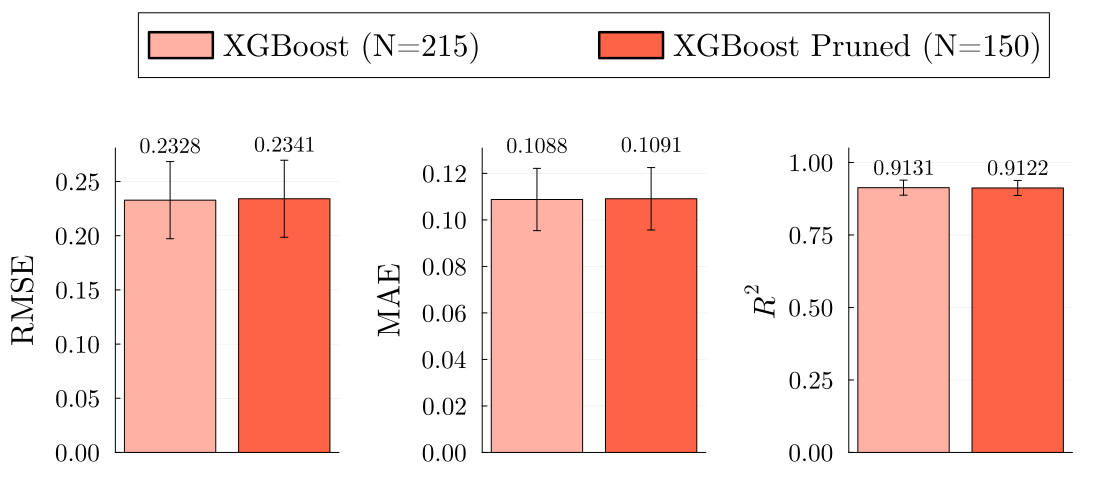

In [392]:
# step 5 — plot phase 3 comparison
# p = plot_model_comparison([winner_tuned, pruned_result])
p = compare_model_comparison(ModelResult[]; csv_path="results/model_comparison_n=150.csv")

#Plots.savefig(p, "figures/compare_tuned_vs_pruned-05-22-2025-n=150.pdf")

## Phase 4 - Final Evaluation

1. Take single best model from Phase 3
2. Evaluate it ONCE on Xtest
3. Report test RMSE, MAE, R^2
4. Back-transform to predicted dollars = 10.^predictions

In [397]:
# ============================================================
# PHASE 4 — FINAL EVALUATION
# ============================================================

function evaluate_final_model(model, model_type::Symbol,
                               X_test::Matrix{Float64}, y_test::Vector{Float64},
                               feature_cols::Vector, col_idx::Vector{Int})

    # subset test set to pruned features
    X_test_pruned = X_test[:, col_idx]

    # predict on log scale
    if model_type == :rf
        log_preds = apply_forest(model, X_test_pruned)
    elseif model_type == :xgb
        log_preds = XGBoost.predict(model, DMatrix(X_test_pruned))
    end

    # metrics on log scale
    rmse, mae, r2 = score_predictions(y_test, log_preds)

    # back-transform to dollars
    pred_dollars = 10 .^ log_preds
    true_dollars = 10 .^ y_test

    # dollar-scale metrics
    dollar_residuals  = true_dollars .- pred_dollars
    dollar_rmse       = sqrt(mean(dollar_residuals .^ 2))
    dollar_mae        = mean(abs.(dollar_residuals))
    dollar_ss_res     = sum(dollar_residuals .^ 2)
    dollar_ss_tot     = sum((true_dollars .- mean(true_dollars)) .^ 2)
    dollar_r2         = 1 - dollar_ss_res / dollar_ss_tot

    # median absolute percentage error — more interpretable than RMSE for log-normal
    mdape = median(abs.(dollar_residuals ./ true_dollars) .* 100)
    mape = mean(abs.(dollar_residuals ./ true_dollars) .* 100)

    println("=== PHASE 4 — FINAL TEST SET EVALUATION ===")
    println("\n  Log₁₀ Scale (what the model optimized):")
    @printf("    RMSE: %.4f\n", rmse)
    @printf("    MAE:  %.4f\n", mae)
    @printf("    R²:   %.4f\n", r2)

    println("\n  Dollar Scale (back-transformed):")
    @printf("    RMSE:   \$%.2f\n",   dollar_rmse)
    @printf("    MAE:    \$%.2f\n",   dollar_mae)
    @printf("    R²:     %.4f\n",     dollar_r2)
    @printf("    MdAPE:  %.1f%%\n",   mdape)
    @printf("    MAPE:   %.1f%%\n",   mape)

    println("\n  Interpretation:")
    @printf("    Median prediction is within %.1f%% of true value\n", mdape)
    @printf("    A log RMSE of %.4f means ~%.1fx typical error in dollar terms\n",
        rmse, 10^rmse)

    # results dataframe for further analysis
    results_df = DataFrame(
        true_log       = y_test,
        pred_log       = log_preds,
        true_dollars   = true_dollars,
        pred_dollars   = pred_dollars,
        abs_pct_error  = abs.(dollar_residuals ./ true_dollars) .* 100,
        log_residual   = y_test .- log_preds
    )

    return results_df, (
        log_rmse     = rmse,
        log_mae      = mae,
        log_r2       = r2,
        dollar_rmse  = dollar_rmse,
        dollar_mae   = dollar_mae,
        dollar_r2    = dollar_r2,
        mdape         = mdape,
        mape          = mape
    )
end


# ============================================================
# RUN PHASE 4
# ============================================================

results_df, test_metrics = evaluate_final_model(
    final_model, winner_type,
    X_test, y_test,
    feature_cols, final_col_idx
)



=== PHASE 4 — FINAL TEST SET EVALUATION ===

  Log₁₀ Scale (what the model optimized):
    RMSE: 0.4344
    MAE:  0.3168
    R²:   0.7010

  Dollar Scale (back-transformed):
    RMSE:   $85483887.70
    MAE:    $2481950.14
    R²:     0.0764
    MdAPE:  51.8%
    MAPE:   117.4%

  Interpretation:
    Median prediction is within 51.8% of true value
    A log RMSE of 0.4344 means ~2.7x typical error in dollar terms


(70417×6 DataFrame
   Row │ true_log  pred_log  true_dollars    pred_dollars   abs_pct_error  log ⋯
       │ Float64   Float32   Float64         Float32        Float64        Flo ⋯
───────┼────────────────────────────────────────────────────────────────────────
     1 │  5.01912   5.20176  104501.0            1.59132e5       52.2778     - ⋯
     2 │  6.79635   6.71421       6.25684e6      5.17854e6       17.234
     3 │  6.17589   6.67106       1.4993e6       4.68875e6      212.729      -
     4 │  4.81111   4.84499   64730.7        69982.9              8.11398    -
     5 │  4.61783   4.72007   41479.6        52489.2             26.5421     - ⋯
     6 │  6.63963   6.5478        4.3614e6       3.53022e6       19.0577
     7 │  6.17618   5.40073       1.50031e6      2.51611e5       83.2293
     8 │  6.13796   6.46189       1.37392e6      2.89658e6      110.826      -
   ⋮   │    ⋮         ⋮            ⋮               ⋮              ⋮            ⋱
 70411 │  5.53457   5.59343  342429.0   

In [ ]:
#save results and test metrics to csv for later
#CSV.write("final_test_results_69_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv", results_df)
#CSV.write("final_test_metrics_69_$(Dates.format(now(), "yyyy-mm-dd_HH-MM-SS")).csv", DataFrame(; test_metrics...))

"final_test_metrics_69_2026-05-22_23-48-06.csv"

In [5]:
results_df = CSV.read("n=150/final_test_results_2026-05-22_23-20-06.csv", DataFrame)
test_metrics = CSV.read("n=150/final_test_metrics_n=150-2026-05-22_23-20-06.csv", DataFrame)

Row,log_rmse,log_mae,log_r2,dollar_rmse,dollar_mae,dollar_r2,mdape,mape
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.430218,0.313676,0.706764,8.56e7,2.46e6,0.0742309,51.3268,115.15


In [17]:
using DataFrames, Statistics

function stratified_accuracy(results_df::DataFrame;
    bins = [0, 1e6, 10e6, 100e6, Inf],
    labels = ["<\$1M", "\$1M–\$10M", "\$10M–\$100M", ">\$100M"],
    within_pct_threshold = 20
)
    df = copy(results_df)

    # assign each row to a stratum
    df.stratum = cut_bins(df.true_dollars, bins, labels)

    rows = []
    for label in labels
        subset = filter(r -> r.stratum == label, eachrow(df))
        isempty(subset) && continue

        ape     = [r.abs_pct_error for r in subset]
        n       = length(ape)
        mape    = mean(ape) 
        within  = mean(ape .< within_pct_threshold)
        med_ape = median(ape)
        std_ape = std(ape)

        push!(rows, (
            range       = label,
            n           = n,
            mape_pct    = round(mape, digits=1),
            median_ape  = round(med_ape, digits=1),
            std_ape     = round(std_ape, digits=1),
            within_20   = round(within, digits=3)*100
        ))
    end

    return DataFrame(rows)
end

# helper: assign bin labels (base Julia, no extra packages)
function cut_bins(values::Vector{Float64}, bins::Vector{Float64}, labels::Vector{String})
    result = Vector{String}(undef, length(values))
    for (i, v) in enumerate(values)
        assigned = false
        for j in 1:(length(bins)-1)
            if v >= bins[j] && v < bins[j+1]
                result[i] = labels[j]
                assigned = true
                break
            end
        end
        assigned || (result[i] = "out of range")
    end
    return result
end

# --- run it ---
strata_summary = stratified_accuracy(results_df,
    bins   = [0, 250e3, 1e6, 10e6, 100e6, Inf],
    labels = ["<\$250K", "\$250K–\$1M", "\$1M–\$10M", "\$10M–\$100M", ">\$100M"], within_pct_threshold=20
)
println(strata_summary)

5×6 DataFrame
 Row │ range       n      mape_pct  median_ape  std_ape  within_20 
     │ String      Int64  Float64   Float64     Float64  Float64   
─────┼─────────────────────────────────────────────────────────────
   1 │ <$250K      52040     126.4        46.8   1375.8       24.8
   2 │ $250K–$1M    9794      89.4        57.9    260.4       17.4
   3 │ $1M–$10M     6672      77.2        63.0    149.8       16.4
   4 │ $10M–$100M   1651      72.6        74.1     66.8        8.7
   5 │ >$100M        260      78.4        89.1     29.2        5.8


In [36]:

default(
    fontfamily = "Computer Modern",
    guidefontsize = 16,
    tickfontsize = 14,
    titlefontsize = 20,
    legendfontsize = 12)

function plot_final_results(results_df::DataFrame, test_metrics)

    # 1 — predicted vs actual (log scale)
    p1 = StatsPlots.scatter(results_df.true_log, results_df.pred_log,
        xlabel    = L"Actual (log$_{10}$ scale)",
        ylabel    = L"Predicted (log$_{10}$ scale)",
        title     = "Predicted vs Actual Award Amount",
        label     = false,
        alpha     = 0.3,
        markersize = 2,
        color     = :steelblue,
        size      = (500, 450),
        legend = :topleft
    )
    # perfect prediction line
    min_val = minimum(results_df.true_log)
    max_val = maximum(results_df.true_log)
    StatsPlots.plot!(p1, [min_val, max_val], [min_val, max_val],
        label     = "Perfect Fit",
        color     = :red,
        linestyle = :dash,
        linewidth = 2)

    # 2 — residuals vs predicted (log scale)
    p2 = StatsPlots.scatter(results_df.pred_log, results_df.log_residual,
        xlabel    = L"Predicted (log$_{10}$ scale)",
        ylabel    = L"Residual (log$_{10}$ scale)",
        title     = "Residuals vs Predicted",
        label     = false,
        alpha     = 0.3,
        markersize = 2,
        color     = :steelblue,
        size      = (500, 450),
        legend = :topleft

    )
    StatsPlots.hline!(p2, [0.0],
        color     = :red,
        linestyle = :dash,
        linewidth = 2,
        label     = "zero")

    # 3 — residual distribution
    p3 = Plots.histogram(results_df.log_residual,
        normalize  = :pdf,
        bins       = 60,
        xlabel     = L"Residual (log$_{10}$ scale)",
        ylabel     = "Density",
        title      = "Residual Distribution",
        label      = false,
        color      = :steelblue,
        alpha      = 0.7,
        size       = (500, 450),
        legend = :topleft
    )
    Plots.vline!(p3, [0.0],
        color     = :red,
        linestyle = :dash,
        linewidth = 2,
        label     = "zero")

    # 4 — absolute % error distribution (capped at 200% for readability)
    capped_errors = min.(results_df.abs_pct_error, 200.0)
    p4 = StatsPlots.histogram(capped_errors, #results_df.abs_pct_error,
        normalize  = :pdf,
        bins       = 50,
        xlabel     = "Absolute Percent Error",
        ylabel     = "Density",
        title      = "Percent Error Distribution",
        label      = false,
        color      = "#FFB1A3",
        alpha      = 0.7,
        size       = (500, 450),
        legend = :topleft
    )
    StatsPlots.vline!(p4, [test_metrics.mdape],
        color     = :red,
        linestyle = :dash,
        linewidth = 2,
        label     = "median $(round(test_metrics.mdape, digits=1))%")

    StatsPlots.vline!(p4, [test_metrics.mape],
        color     = :black,
        linestyle = :dash,
        linewidth = 2,
        label     = "mean $(round(test_metrics.mape, digits=1))%")

    StatsPlots.plot(p1, p2, p3, p4,
        layout = (2, 2),
        size   = (1000, 850),
        left_margin   = 5Plots.mm,
        bottom_margin = 5Plots.mm,
        right_margin  = 5Plots.mm,
        top_margin    = 5Plots.mm,

        #plot_title = "Final Model Evaluation — Test Set"
    )
end


plot_final_results (generic function with 1 method)

In [38]:
#pick out values where the true award is less than 100 million dollars
Reults_df_smol = filter(row -> row.true_dollars < 100e6, results_df)


Row,true_log,pred_log,true_dollars,pred_dollars,abs_pct_error,log_residual
,Float64,Float64,Float64,Float64,Float64,Float64
1,5.01912,5.18884,104501.0,1.54467e5,47.814,-0.169716
2,6.79635,6.77332,6.25684e6,5.93359e6,5.16627,0.0230372
3,6.17589,6.51179,1.4993e6,3.2493e6,116.721,-0.335901
4,4.81111,4.7056,64730.7,50769.2,21.5685,0.10551
5,4.61783,4.71931,41479.6,52397.1,26.3201,-0.101473
6,6.63963,6.55215,4.3614e6,3.56574e6,18.2433,0.0874769
7,6.17618,5.48313,1.50031e6,3.04181e5,79.7254,0.693049
8,6.13796,6.47535,1.37392e6,2.98778e6,117.463,-0.337385
9,6.2115,6.17928,1.62742e6,1.51104e6,7.15116,0.0322235


In [343]:
worst_idx = argmax(results_df.abs_pct_error)
plot_df   = results_df[1:end .!= worst_idx, :]

Row,true_log,pred_log,true_dollars,pred_dollars,abs_pct_error,log_residual
,Float64,Float32,Float64,Float32,Float64,Float64
1,5.01912,5.15518,104501.0,1.42948e5,36.7906,-0.136056
2,6.79635,6.91546,6.25684e6,8.23123e6,31.5558,-0.11911
3,6.17589,6.732,1.4993e6,5.3951e6,259.842,-0.556112
4,4.81111,4.79456,64730.7,62310.5,3.73895,0.0165494
5,4.61783,4.686,41479.6,48528.9,16.9946,-0.068166
6,6.63963,6.38338,4.3614e6,2.4176e6,44.5683,0.256242
7,6.17618,5.38059,1.50031e6,240207.0,83.9895,0.795594
8,6.13796,6.58445,1.37392e6,3.84109e6,179.571,-0.446491
9,6.2115,6.14303,1.62742e6,1.39004e6,14.5862,0.0684722


In [39]:
p = plot_final_results(Reults_df_smol, test_metrics)
#savefig(p, "final_evaluation_plots_using_full_model_05-07-2026-1905.png")

MethodError: MethodError: no method matching round(::Vector{Float64}, ::RoundingMode{:Nearest}; digits::Int64)
The function `round` exists, but no method is defined for this combination of argument types.

Closest candidates are:
  round(!Matched::DecFP.Dec32, ::RoundingMode{:Nearest}) got unsupported keyword argument "digits"
   @ DecFP ~/.julia/packages/DecFP/1rlvE/src/DecFP.jl:495
  round(!Matched::DecFP.Dec128, ::RoundingMode{:Nearest}) got unsupported keyword argument "digits"
   @ DecFP ~/.julia/packages/DecFP/1rlvE/src/DecFP.jl:495
  round(!Matched::BigFloat, ::RoundingMode{:Nearest}) got unsupported keyword argument "digits"
   @ Base mpfr.jl:1123
  ...


In [ ]:
#Plots.savefig(p, "figures/final_evaluation_plots_05-22-2026-n=69.pdf")

"/Users/paola/Docs/dev/phantom_project/project 1 - estimating potential total value/ALL-COL-FINAL/figures/final_evaluation_plots_05-22-2026-n=69.pdf"

In [30]:
1-46/298
1-352068/745848
1-352068/628590
1-628590/745848
(628590-429517)/745848
(429517-352068)/745848





0.1038401926397872

In [32]:
maximum(results_df.true_dollars)

1.790239030440999e10